# 03 · Logistic regression by hand

Maths unit **M5**. R3 is a weighted, L2-regularised logistic regression on standardised features. This notebook does four things with the real 50,000-image pool:

1. checks the M5 worked example by hand;
2. trains the hand-written gradient-descent solver (`rec/logreg_numpy.py`) and scikit-learn (`rec/r3_logreg.py`) on the same simulated profile, and shows that they agree;
3. shows what λ does to the weights and to the scores over the pool;
4. shows what the skip weight does.

Read `backend/visualtaste/rec/logreg_numpy.py` first: its docstring has every formula used here.

**Everything below uses a simulated user** (`eval/sim.py`, variant S1). Real labels only exist once Alen swipes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

from visualtaste.api.deps import AppState
from visualtaste.config import get_settings
from visualtaste.eval.sim import make_variant_user
from visualtaste.rec import logreg_numpy
from visualtaste.rec.features import design_matrix
from visualtaste.rec.labels import ACTION_TO_TARGET, label_weights
from visualtaste.rec.r3_logreg import LAMBDA_GRID, fit_sklearn, tune_lambda

state = AppState(get_settings())
state.load()
features = state.require_features()
X_pool = design_matrix(features, ("sig",))
print(f"pool: {X_pool.shape[0]:,} images x {X_pool.shape[1]} standardised SigLIP PCA components")
print(f"column means ~0: {abs(X_pool.mean(0)).max():.1e}; column stds ~1: {X_pool.std(0).min():.3f}..{X_pool.std(0).max():.3f}")

Archive ladder reached rule 5: no external drive and only 54.1 GB free. Using the internal fallback by prior decision (docs/DECISIONS.md #2).


pool: 50,000 images x 128 standardised SigLIP PCA components
column means ~0: 5.2e-08; column stds ~1: 1.000..1.000


## 1 · The M5 example, by hand

w = (2, −1), b = 0, x = (0.8, 0.6), y = 0 (he disliked it). The logit is z = w·x + b = 1.0, so p = σ(1) ≈ 0.731 and the loss is −ln(1 − 0.731) ≈ 1.313. The gradient is (p − y)·x. One step with η = 0.5 should move p towards 0.

In [2]:
w, b = np.array([2.0, -1.0]), 0.0
x, y, s = np.array([[0.8, 0.6]]), np.array([0.0]), np.array([1.0])

p = logreg_numpy.sigmoid(x @ w + b)[0]
loss = logreg_numpy.objective(w, b, x, y, s, lam=0.0)
w1, b1 = logreg_numpy.gd_step(w, b, x, y, s, lam=0.0, eta=0.5)
print(f"p = {p:.3f}, loss = {loss:.3f}")
print(f"after one step: w = {np.round(w1, 3)}, b = {b1:.3f}, new p = {logreg_numpy.sigmoid(x @ w1 + b1)[0]:.3f}")

p = 0.731, loss = 1.313
after one step: w = [ 1.708 -1.219], b = -0.366, new p = 0.567


## 2 · A simulated profile, and two solvers

A simulated S1 user is shown 600 random pool images, a stand-in for a cold-start history. Every verdict becomes a label with the production weights (save 2.0, like 1.0, dislike 1.0, skip 0.25).

In [3]:
rng = np.random.default_rng(1729)
user = make_variant_user("S1_semantic", features, seed=1729, cluster_labels=features.cluster64)
shown = rng.choice(len(features), 600, replace=False)
actions = user.react_rows(features, shown)

weights = label_weights(0.25)
X = X_pool[shown].astype(np.float64)
y = np.array([ACTION_TO_TARGET[a] for a in actions], dtype=np.float64)
s = np.array([weights[a] for a in actions])
print({a: actions.count(a) for a in sorted(set(actions))})

tuning = tune_lambda(X, y, s)
lam = tuning.lam
print(f"lambda chosen by time-ordered validation: {lam:g}")

{'dislike': 236, 'like': 310, 'skip': 54}


lambda chosen by time-ordered validation: 1


gradient descent: 48 iterations, converged=True, |g| = 8.8e-09
largest weight difference vs scikit-learn: 4.82e-09; bias difference 3.58e-08


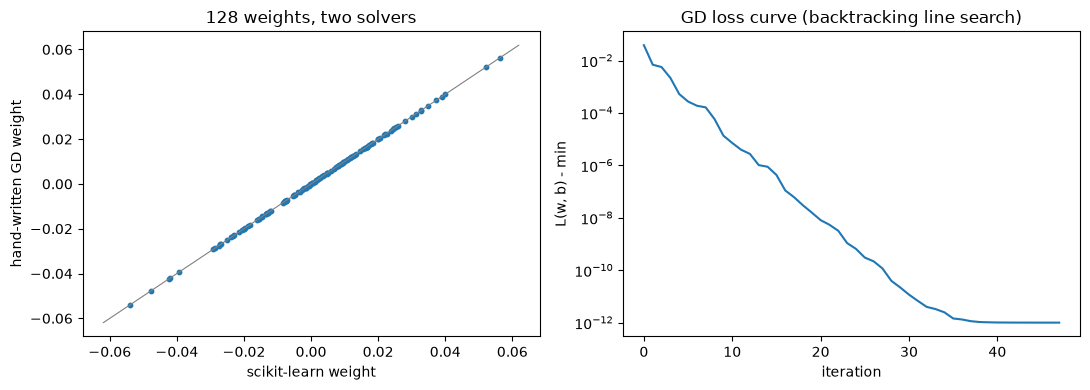

In [4]:
hand = logreg_numpy.fit(X, y, s, lam=lam, record_every=1)
w_sk, b_sk = fit_sklearn(X, y, s, lam)

print(f"gradient descent: {hand.iterations:,} iterations, converged={hand.converged}, |g| = {hand.gradient_norm:.1e}")
print(f"largest weight difference vs scikit-learn: {np.abs(hand.w - w_sk).max():.2e}; bias difference {abs(hand.b - b_sk):.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(w_sk, hand.w, s=10)
lim = np.abs(w_sk).max() * 1.1
axes[0].plot([-lim, lim], [-lim, lim], color="grey", lw=0.8)
axes[0].set(xlabel="scikit-learn weight", ylabel="hand-written GD weight", title="128 weights, two solvers")
history = np.array(hand.loss_history)
axes[1].semilogy(history - history.min() + 1e-12)
axes[1].set(xlabel="iteration", ylabel="L(w, b) - min", title="GD loss curve (backtracking line search)")
plt.tight_layout()

The two solvers land on the same 128 weights, far inside the 1e-3 that `tests/test_logreg.py` asserts.

How many iterations gradient descent needs depends on the problem's *conditioning*: how different the loss surface's steepest and flattest directions are. Standardising the features is what keeps that ratio small. The next cell runs the same fit on the raw, unstandardised PCA features, where the components' scales differ by a factor of six, and counts iterations both ways.

In [5]:
raw = features.pca[shown].astype(np.float64)
for lam_i in (1.0, 1e-2, 1e-3):
    standardised = logreg_numpy.fit(X, y, s, lam=lam_i)
    unscaled = logreg_numpy.fit(raw, y, s, lam=lam_i, max_iter=50_000)
    print(f"λ = {lam_i:<6g} standardised: {standardised.iterations:>6,} iterations   "
          f"raw PCA: {unscaled.iterations:>6,} iterations (converged={unscaled.converged})")

λ = 1      standardised:     48 iterations   raw PCA:     30 iterations (converged=True)
λ = 0.01   standardised:     48 iterations   raw PCA:    155 iterations (converged=True)


λ = 0.001  standardised:     62 iterations   raw PCA:  1,202 iterations (converged=True)


Measured on this profile (2026-10-31): at λ = 1e-3 the raw features need **1,202** iterations against **62** standardised, about 20 times as many; at λ = 0.01, 155 against 48. At λ = 1 the penalty dominates the curvature and the raw problem is slightly faster (30 against 48), because its tiny feature values leave the weights near zero anyway.

So standardisation does two jobs. It makes the L2 penalty treat every dimension equally (the `rec/features.py` docstring), and it keeps the optimisation well conditioned when λ is small, which is exactly when a lot of labels make a small λ the right choice.

## 3 · What λ does

A larger λ shrinks ‖w‖ and squeezes every score towards the base rate. A smaller one lets the model fit the history closely, but on 480 training labels that means fitting noise. The chosen λ sits where the validation loss, on the *latest* 20% of labels, bottoms out.

λ = 0.0001   validation log loss 0.8850
λ = 0.0003   validation log loss 0.8832
λ = 0.001    validation log loss 0.8770
λ = 0.003    validation log loss 0.8616
λ = 0.01     validation log loss 0.8230
λ = 0.03     validation log loss 0.7679
λ = 0.1      validation log loss 0.7100
λ = 0.3      validation log loss 0.6822
λ = 1        validation log loss 0.6787
λ = 3        validation log loss 0.6835
λ = 10       validation log loss 0.6871


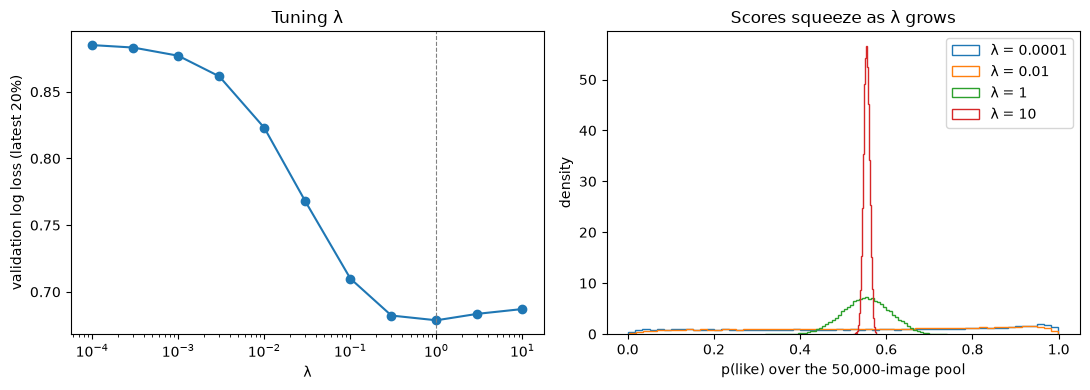

In [6]:
norms, spreads = [], []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lam_i in (1e-4, 1e-2, 1.0, 10.0):
    w_i, b_i = fit_sklearn(X, y, s, lam_i)
    scores = expit(X_pool @ w_i + b_i)
    axes[1].hist(scores, bins=60, histtype="step", density=True, label=f"λ = {lam_i:g}")
grid = sorted(tuning.curve)
axes[0].semilogx(grid, [tuning.curve[g] for g in grid], marker="o")
axes[0].axvline(lam, color="grey", ls="--", lw=0.8)
axes[0].set(xlabel="λ", ylabel="validation log loss (latest 20%)", title="Tuning λ")
axes[1].set(xlabel="p(like) over the 50,000-image pool", ylabel="density", title="Scores squeeze as λ grows")
axes[1].legend()
plt.tight_layout()
for g in grid:
    print(f"λ = {g:<8g} validation log loss {tuning.curve[g]:.4f}")

## 4 · What the skip weight does

Simulated skips are drawn *before* the like decision, so they carry no information about taste. Labelling them y = 0 at weight 0.25 tells the model that skipped images are slightly disliked, which is noise. Excluding them should be no worse. Weight 0 is identical to excluding them (DECISIONS #20). The full 20-seed comparison is the `phase9_skip` study in `docs/EVALUATION.md`.

In [7]:
verdicts = np.array(actions)
for name, keep, weight_table in (
    ("skip = 0.25", np.ones(len(y), bool), label_weights(0.25)),
    ("skip = 1.0", np.ones(len(y), bool), label_weights(1.0)),
    ("excluded", verdicts != "skip", label_weights(0.25)),
):
    s_i = np.array([weight_table[a] for a in actions])[keep]
    X_i, y_i = X[keep], y[keep]
    t = tune_lambda(X_i, y_i, s_i)
    w_i, b_i = fit_sklearn(X_i, y_i, s_i, t.lam)
    # Judge every arm on the same thing: the true p(like) the simulator knows.
    truth = user.like_probability(features.siglip)
    predicted = expit(X_pool @ w_i + b_i)
    corr = np.corrcoef(predicted, truth)[0, 1]
    print(f"{name:<12} λ = {t.lam:<6g} correlation with the true p(like) over the pool: {corr:.3f}")

skip = 0.25  λ = 1      correlation with the true p(like) over the pool: 0.574


skip = 1.0   λ = 1      correlation with the true p(like) over the pool: 0.568


excluded     λ = 1      correlation with the true p(like) over the pool: 0.571


Correlation with the simulator's true p(like) is a luxury only a simulation has: with real data the truth is never known, which is why `docs/EVALUATION.md` judges the arms by replay log loss and like rate instead.